# 重分配订正的批量调度

流程与 `batch_schedule_and_verify.ipynb` 相同：等高层要素估两套地形增强，降水与模式增强都插到 1 km 地形网格，再和实况比 Bias / RMSE。

**差别**

- 订正使用 `RedistributeOrographicEnhancement`：在 1 km 网格上用「1 km 增强 − 模式增强」重分配已有降水。低于 0.1 mm/h 的格点不改，有雨格点上的增减相抵。
- 订正结果不写回。增强场和订正降水都只留在内存里，每个时次算完即丢。
- 检验表写到 `output/verify/redistribute_hourly.csv`，不覆盖原来的 `hourly.csv`。

**时间与量**

- EC 起报与 `dtime` 是世界时。有效世界时 = 起报 + 时效。
- `APCP01` 每 3 h 一个文件，数值是以有效时为终点的 **3 小时累计平均**（按 `mm h-1` 使用，不再除以 3）。
- CMPAS 文件名和文件内 `time` 都是北京时，逐小时。北京时 = 有效世界时 + 8 h。
- 检验取北京时终点及其前两个整点，三小时平均后与预报比较。
- 时效 `000` 没有 `APCP01`，不进入订正。


## 1. 准备


In [1]:
from __future__ import annotations

import sys
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import meteva_base as meb

PKG = Path("..").resolve()
sys.path[:0] = [str(PKG.parent), str(PKG)]

from orographic_precipitation_downscaling.cli.orographic_enhancement_cli import process as oe_process
from orographic_precipitation_downscaling.src import RedistributeOrographicEnhancement

DATA = PKG / "resource" / "data"
OBS_ROOT = PKG / "resource" / "CMPAS_APCP"
OUT = DATA / "output"

OROG_MODEL = str(PKG / "resource" / "ancil" / "EC_D1D_orography_20km.nc")
OROG = str(PKG / "resource" / "ancil" / "HGT_M_1KM_CHINA.nc")


def nc_index(root: Path) -> dict:
    """递归列出目录下的 nc，以文件名主干为键。"""
    files = meb.path_tools.get_path_list_in_dir(str(root))
    return {Path(p).stem: p for p in files if str(p).endswith(".nc")}


tmp_ix = nc_index(DATA / "TMP")
rh_ix = nc_index(DATA / "RH")
pres_ix = nc_index(DATA / "PRES")
u_ix = nc_index(DATA / "UGRD")
v_ix = nc_index(DATA / "VGRD")
apcp_list = meb.path_tools.get_path_list_in_dir(str(PKG / "resource" / "EC" / "APCP01"))
apcp_list = sorted(p for p in apcp_list if str(p).endswith(".nc") and Path(p).stem in tmp_ix)


def parse_tag(tag: str):
    init_s, lead_s = tag.split(".")
    return datetime.strptime(init_s, "%Y%m%d%H"), int(lead_s)


def cmpas_path(bjt: datetime) -> Path:
    """北京时整点对应的逐小时实况路径。"""
    return OBS_ROOT / f"{bjt:%Y}" / f"{bjt:%Y%m%d}" / f"BJT_{bjt:%y%m%d%H}.000.nc"


def obs_3h_mean(valid_utc: datetime, grid):
    """以有效世界时为终点，取北京时三小时实况平均，并落到目标网格。"""
    bjt_end = valid_utc + timedelta(hours=8)
    hours = [bjt_end - timedelta(hours=2), bjt_end - timedelta(hours=1), bjt_end]
    acc = None
    last = None
    for bjt in hours:
        path = cmpas_path(bjt)
        if not path.exists():
            raise FileNotFoundError(path)
        da = meb.read_griddata_from_nc(str(path))
        da = meb.interp_gg_linear(da, grid, outer_value=np.nan)
        values = np.asarray(da.values, dtype=np.float64)
        acc = values if acc is None else acc + values
        last = da
    out = last.copy(data=(acc / 3.0).astype(np.float32))
    out.attrs["units"] = "mm h-1"
    out.name = "cmpas_3h_mean"
    return out


print("n forecasts", len(apcp_list))
print("example APCP", apcp_list[0])


d:\workspace\test\.venv\Lib\site-packages\meteva_base\basicdata\const.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


n forecasts 14
example APCP D:\workspace\test\00temp\orographic_precipitation_downscaling\resource\EC\APCP01\2026\20260727\NC\2026072700.003.nc


## 2. 批量估增强 → 重分配订正 → 检验

模式增强插到 1 km，与高分辨率增强、插值后的降水一起交给 `RedistributeOrographicEnhancement`。订正场不写文件。只保留第 1 个时次的三张图所用数组，其余时次在算出 Bias / RMSE 后释放。


In [2]:
def _bias_rmse(pred: np.ndarray, obs: np.ndarray) -> tuple[float, float, int]:
    mask = np.isfinite(pred) & np.isfinite(obs) & (np.abs(pred) < 1e10) & (np.abs(obs) < 1e10)
    if not np.any(mask):
        return float("nan"), float("nan"), 0
    diff = pred[mask] - obs[mask]
    return float(np.mean(diff)), float(np.sqrt(np.mean(diff**2))), int(mask.sum())


redistribute = RedistributeOrographicEnhancement()
dest = meb.read_griddata_from_nc(OROG)
dest.attrs["units"] = "m"
grid1km = meb.get_grid_of_data(dest)

rows = []
sample = None
for apcp in apcp_list:
    tag = Path(apcp).stem
    init, lead = parse_tag(tag)
    valid = init + timedelta(hours=lead)

    oe_model = oe_process(
        tmp_ix[tag], rh_ix[tag], pres_ix[tag], u_ix[tag], v_ix[tag],
        OROG_MODEL,
        output_path=None,
    )
    oe_high = oe_process(
        tmp_ix[tag], rh_ix[tag], pres_ix[tag], u_ix[tag], v_ix[tag],
        OROG,
        output_path=None,
    )

    precip = meb.read_griddata_from_nc(apcp)
    precip.attrs["units"] = "mm h-1"
    before = meb.interp_gg_linear(precip, grid1km, outer_value=np.nan)
    before.attrs["units"] = "mm h-1"
    before.name = "precipitation_rate"
    oe_model_1km = meb.interp_gg_linear(oe_model, grid1km, outer_value=np.nan)
    oe_model_1km.attrs["units"] = oe_model.attrs.get("units") or "m s-1"
    if not (oe_high.attrs.get("units") or "").strip():
        oe_high.attrs["units"] = "m s-1"
    after = redistribute(before, oe_high, oe_model_1km)
    obs = obs_3h_mean(valid, grid1km)

    b = np.asarray(obs.values, dtype=float).ravel()
    a0 = np.asarray(before.values, dtype=float).ravel()
    a1 = np.asarray(after.values, dtype=float).ravel()
    bias0, rmse0, n = _bias_rmse(a0, b)
    bias1, rmse1, _ = _bias_rmse(a1, b)
    finite = np.isfinite(a0) & np.isfinite(a1)
    sum0 = float(a0[finite].sum())
    sum1 = float(a1[finite].sum())
    rows.append({
        "tag": tag,
        "valid_utc": valid.strftime("%Y%m%d%H"),
        "bjt_end": (valid + timedelta(hours=8)).strftime("%Y%m%d%H"),
        "bias_before": bias0,
        "rmse_before": rmse0,
        "bias_after": bias1,
        "rmse_after": rmse1,
        "delta_rmse": rmse1 - rmse0,
        "sum_before": sum0,
        "sum_after": sum1,
        "n": n,
    })
    print(
        f"{tag}  before bias={bias0:.3f} rmse={rmse0:.3f} | "
        f"after bias={bias1:.3f} rmse={rmse1:.3f} | "
        f"Δrmse={rmse1 - rmse0:+.3f} | "
        f"Δsum={sum1 - sum0:+.3f} mm/h"
    )
    if sample is None:
        sample = {"tag": tag, "valid": valid, "before": before, "after": after, "obs": obs}

hourly = pd.DataFrame(rows)
ver_dir = OUT / "verify"
ver_dir.mkdir(parents=True, exist_ok=True)
hourly_path = ver_dir / "redistribute_hourly.csv"
hourly.to_csv(hourly_path, index=False)
print(
    f"mean  before bias={hourly.bias_before.mean():.3f} rmse={hourly.rmse_before.mean():.3f} | "
    f"after bias={hourly.bias_after.mean():.3f} rmse={hourly.rmse_after.mean():.3f} | "
    f"Δrmse={hourly.delta_rmse.mean():+.3f} mm/h"
)
print("table", hourly_path)


2026072700.003  before bias=0.038 rmse=0.705 | after bias=0.038 rmse=0.706 | Δrmse=+0.001 | Δsum=+0.000 mm/h
2026072700.006  before bias=0.088 rmse=0.804 | after bias=0.088 rmse=0.806 | Δrmse=+0.002 | Δsum=-0.000 mm/h
2026072700.009  before bias=0.091 rmse=1.172 | after bias=0.091 rmse=1.174 | Δrmse=+0.001 | Δsum=+0.000 mm/h
2026072700.012  before bias=-0.017 rmse=1.181 | after bias=-0.017 rmse=1.182 | Δrmse=+0.001 | Δsum=-0.000 mm/h
2026072700.015  before bias=-0.048 rmse=0.951 | after bias=-0.048 rmse=0.952 | Δrmse=+0.001 | Δsum=+0.000 mm/h
2026072700.018  before bias=0.030 rmse=1.001 | after bias=0.030 rmse=1.001 | Δrmse=+0.001 | Δsum=-0.000 mm/h
2026072700.021  before bias=0.035 rmse=1.211 | after bias=0.035 rmse=1.212 | Δrmse=+0.001 | Δsum=+0.000 mm/h
2026072800.003  before bias=0.058 rmse=0.851 | after bias=0.058 rmse=0.852 | Δrmse=+0.001 | Δsum=-0.000 mm/h
2026072800.006  before bias=0.119 rmse=0.888 | after bias=0.119 rmse=0.890 | Δrmse=+0.002 | Δsum=-0.000 mm/h
2026072800.009 

## 3. 三张图（第 1 个时次）

1 订正前（mm/h）　2 订正后（mm/h）　3 实况 3 小时平均（mm/h）  
三张图共用同一套色标。细网格绘图抽稀。图只在界面显示，不写文件。


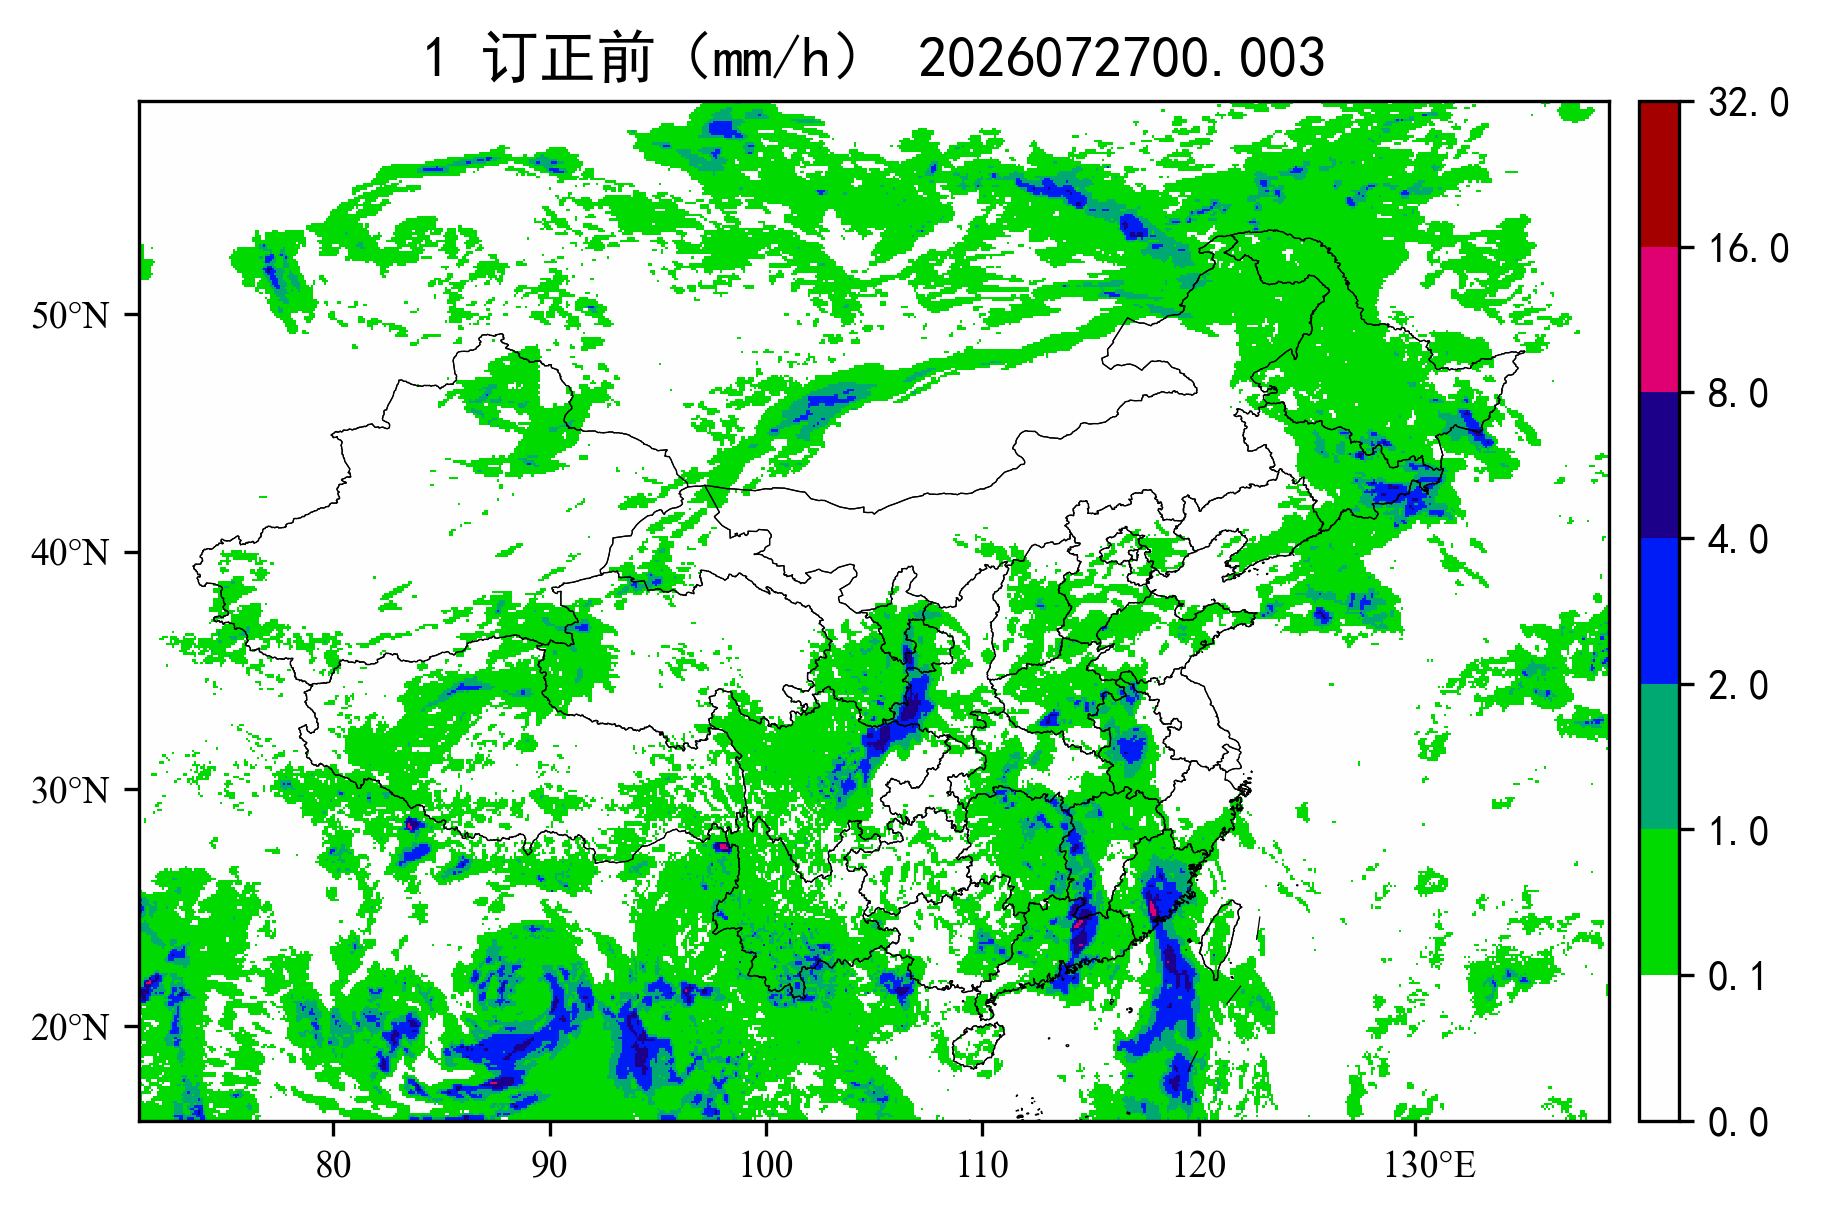

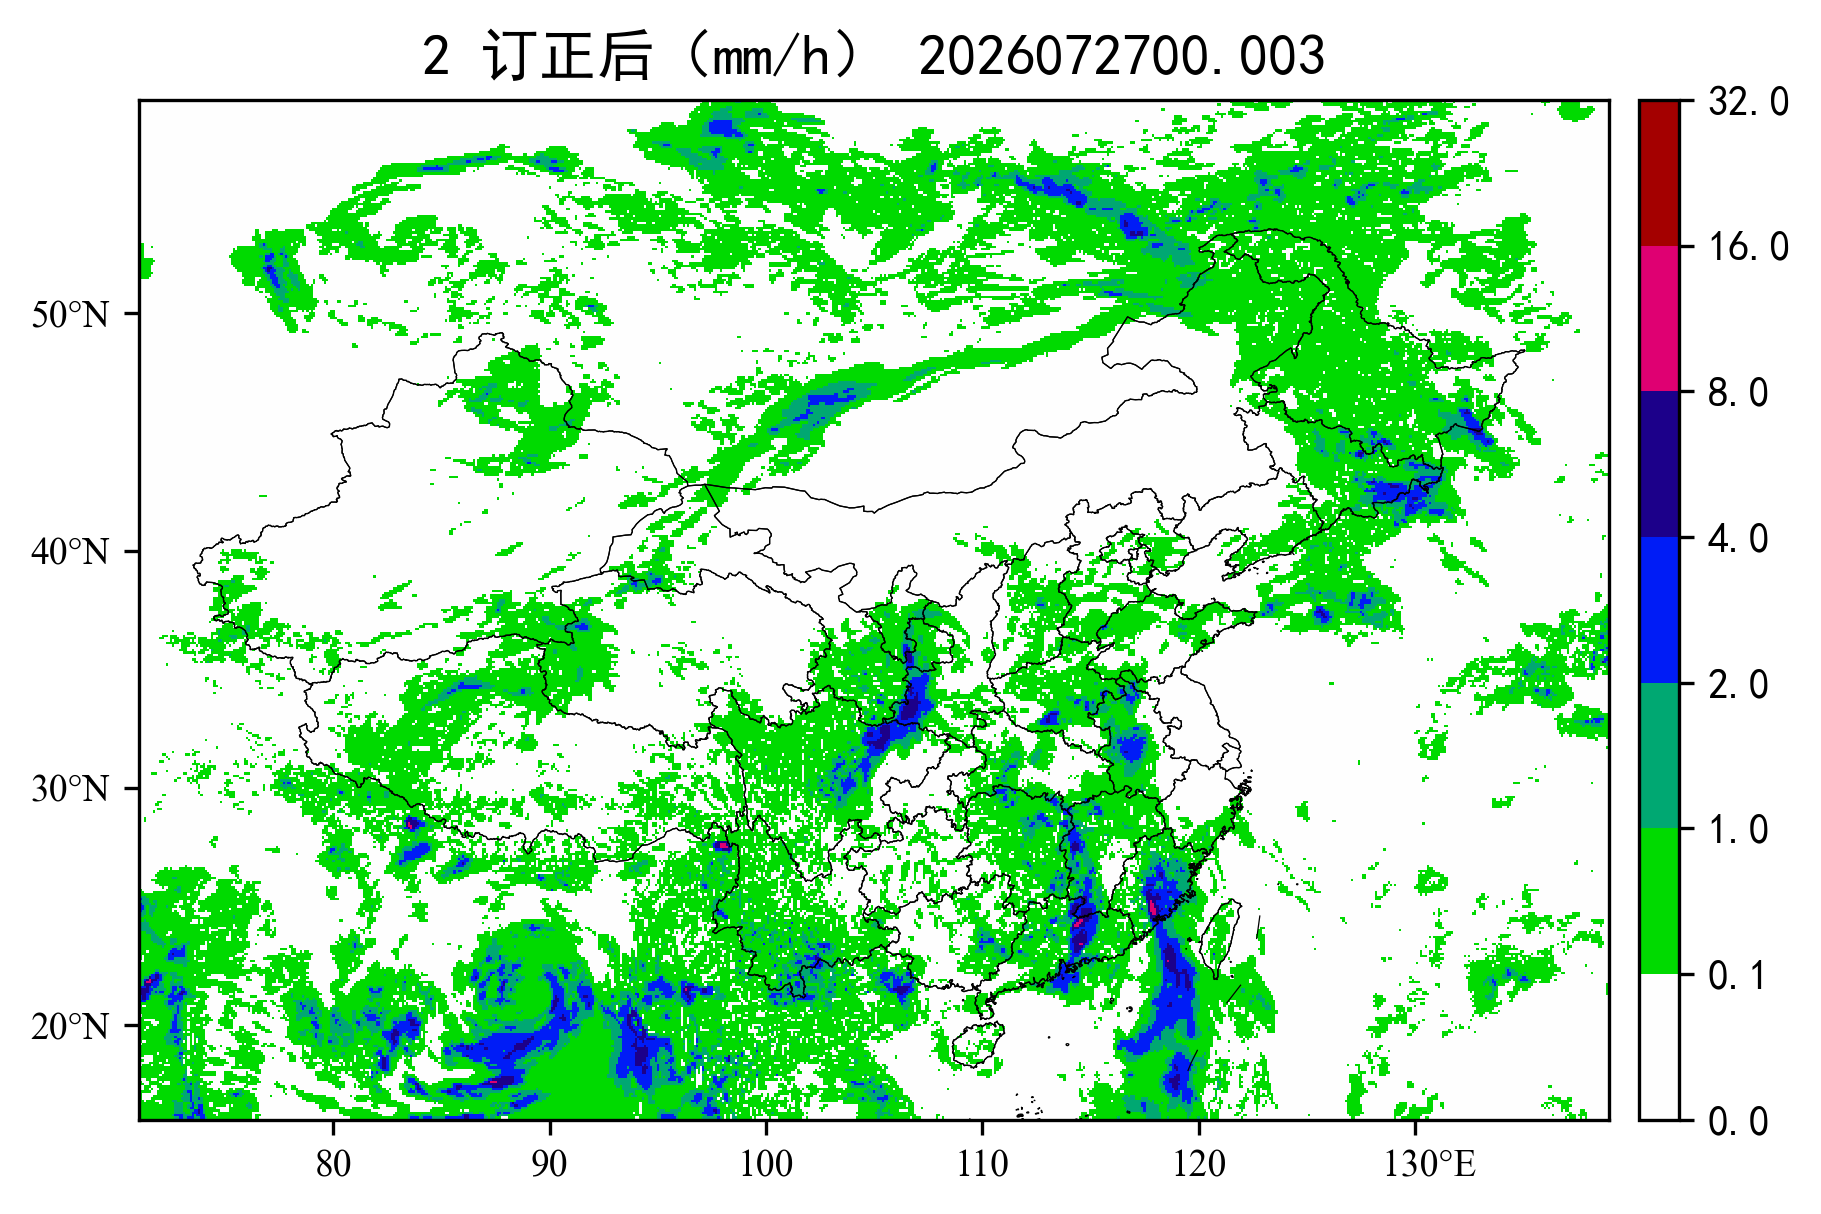

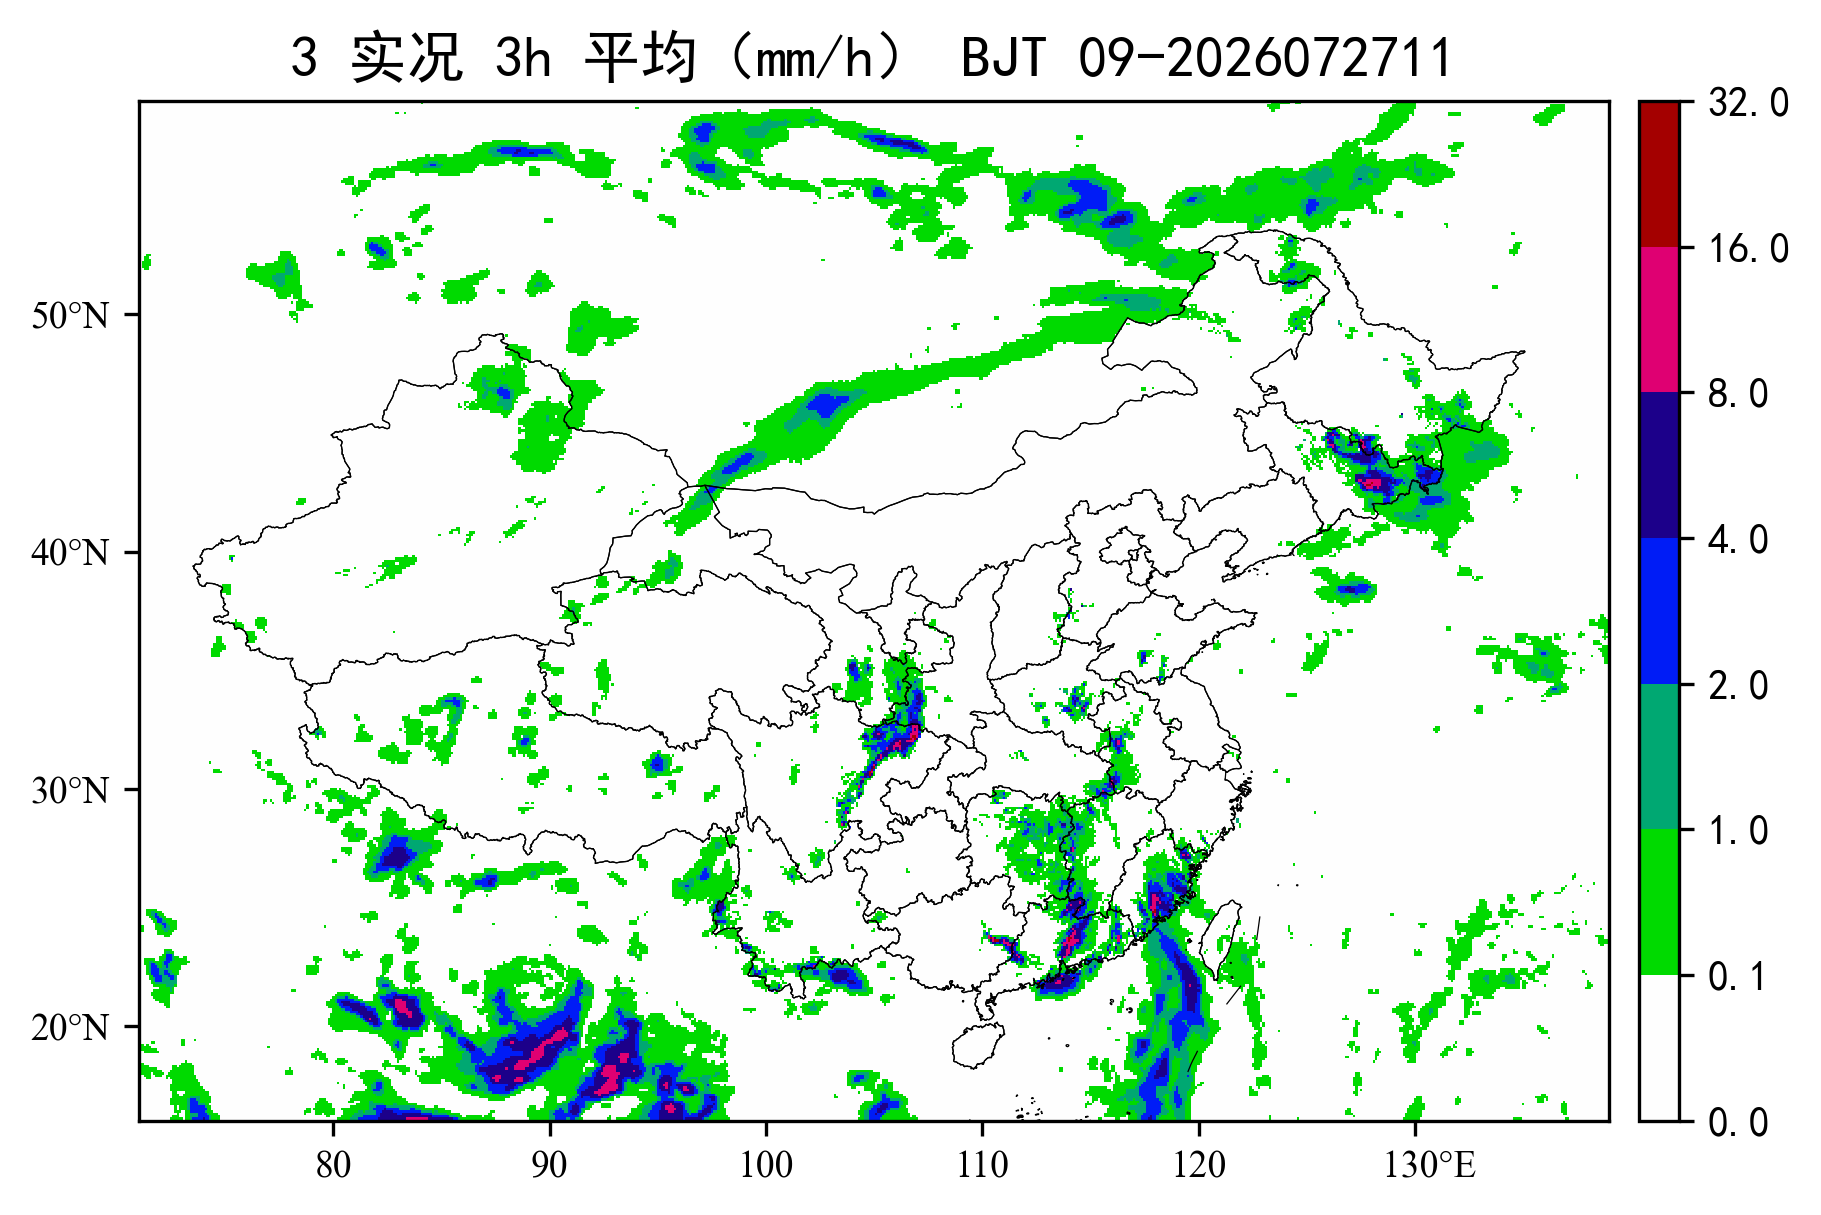

In [3]:
from meteva_base.tool.plot_tools import pcolormesh_2d_grid

tag = sample["tag"]
valid = sample["valid"]
step = 10
before = sample["before"].isel(lat=slice(None, None, step), lon=slice(None, None, step))
after = sample["after"].isel(lat=slice(None, None, step), lon=slice(None, None, step))
obs = sample["obs"].isel(lat=slice(None, None, step), lon=slice(None, None, step))

both = np.concatenate([
    np.asarray(before.values, dtype=float).ravel(),
    np.asarray(after.values, dtype=float).ravel(),
    np.asarray(obs.values, dtype=float).ravel(),
])
both = both[np.isfinite(both) & (both >= 0) & (both < 1e10)]
hi = max(float(np.nanpercentile(both, 99)), 1.0)
clevs = [0, 0.1, 1, 2, 4, 8, 16, 32]
while clevs[-1] < hi and len(clevs) < 19:
    clevs.append(clevs[-1] * 2)

bjt = valid + timedelta(hours=8)
pcolormesh_2d_grid(
    before, save_path=None,
    title=f"1 订正前（mm/h） {tag}",
    clevs=clevs, cmap="rain_1h", show=True,
)
pcolormesh_2d_grid(
    after, save_path=None,
    title=f"2 订正后（mm/h） {tag}",
    clevs=clevs, cmap="rain_1h", show=True,
)
pcolormesh_2d_grid(
    obs, save_path=None,
    title=f"3 实况 3h 平均（mm/h） BJT {bjt - timedelta(hours=2):%H}-{bjt:%Y%m%d%H}",
    clevs=clevs, cmap="rain_1h", show=True,
)
